In [87]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, BayesianRidge, Ridge
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)  
pd.set_option('display.max_columns', None)  
pd.set_option('display.expand_frame_repr', False)

## Utility Functions

In [88]:
def load_node_profile(node):
    filepath = f'../../tool/infrastructure-profiler/profiles/{node}.csv'

    with open(filepath) as f:
        data = f.readlines()[1].split(',')

    return {
        'ram': int(data[1].strip()),
        'cores': int(data[2].strip()),
        'io_read': float(data[3].strip()),
        'io_write': float(data[4].strip()),
        'sysbench': float(data[5].strip()),
        'z7b': float(data[6].strip()),
        'bench_time': float(data[7].strip())
    }

def combine_df(input_df, trace_df):
    rows = []

    for name, group in input_df.groupby('name'):
        no_files = str(len(group))
        filepaths = group['path']
        paths = ','.join([filepath.split('/')[-1].split('.')[-1] for filepath in filepaths])
        total_size = group['size'].sum() / 1073741824  # convert from B to GiB

        if len(trace_df[trace_df['name'] == name]) > 0:
            task_record = trace_df[trace_df['name'] == name].iloc[0]
            task_realtime = task_record['realtime']
            task_difftime = task_record['complete'] - task_record['start']
            task_memory = task_record['memory'] / 1073741824  # convert from B to GiB
            read_bytes = task_record['read_bytes']  # remain in B
            write_bytes = task_record['write_bytes']  # remain in B
            if task_difftime > (1.2 * task_realtime):
                task_runtime = task_realtime
            else:
                task_runtime = task_realtime
            short_name = task_record['name'].split(':')[-2] + ':' + task_record['name'].split(':')[-1].split(' ')[0]
            row = [task_record['task_id'], task_record['name'], task_record['%cpu'], 
                task_record['start'], task_record['complete'], task_runtime, 
                no_files, paths, total_size, short_name, task_record['hostname'], task_memory, read_bytes, write_bytes]
            rows.append(row) 
        else:
            print('err:', name)

    combined = pd.DataFrame(rows, columns=['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'memory', 'read_bytes', 'write_bytes'])
    return combined

def load_profiling_runs(node, workflows, samples, node_profiles):
    node_profile = node_profiles[node]
    runs = {}

    for workflow, samples in zip(workflows, samples):
        runs[workflow] = {}

        for sample in samples:
            sample_dir = f'{node}/{workflow}/{sample}/'
            input_df = pd.read_csv(sample_dir + 'input.csv', sep=';')
            trace_df = pd.read_csv(sample_dir + 'trace.csv')
            runs[workflow][sample] = combine_df(input_df, trace_df)

    return (node_profile, runs)

def load_workflow_execution(cluster, workflow, iteration):
    execution_dir = f'../{cluster}/{workflow}/{iteration}/'
    input_df = pd.read_csv(execution_dir + 'input.csv', sep=';')
    trace_df = pd.read_csv(execution_dir + 'trace.csv')
    return combine_df(input_df, trace_df)

def load_ichnos_trace(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    trace_loc = f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-trace.csv'
    return pd.read_csv(trace_loc)

def process_ichnos_summary(raw):
    core_total_energy = float(raw[7].split(': ')[-1][:-3])
    mem_dynamic_energy = float(raw[9].split(': ')[-1][:-3])
    mem_static_energy = float(raw[15].split(': ')[-1][:-3])
    return {
        'core_total': core_total_energy, 
        'mem_dynamic': mem_dynamic_energy, 
        'mem_static': mem_static_energy, 
        'total': core_total_energy + mem_dynamic_energy + mem_static_energy
    } 

def load_ichnos_summary(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    with open(f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-summary.txt', 'r') as file:
        raw = file.readlines()
    raw = [line.strip() for line in raw]
    return process_ichnos_summary(raw)

def load_profiling_ichnos_summary(node, workflow, sample, gov):
    filename = f'ichnos/{node}-{workflow}-{sample}-{gov}-summary.txt'
    with open(filename, 'r') as file:
        raw = file.readlines()
    raw = [line.strip() for line in raw]
    return process_ichnos_summary(raw)

def load_rapl_summary(cluster, workflow, iteration):
    rapl_vals = pd.read_csv(f'../{cluster}/{workflow}-runs.csv')
    return rapl_vals.iloc[[iteration - 1]]

def load_power_model(node, setting=''):
    if setting != '':
        filename = f'{setting}-model.txt'
    else: 
        filename = 'model.txt'

    with open(f'../../tool/infrastructure-profiler/raw/{node}/{filename}', 'r') as f:
        data = [line.strip() for line in f.readlines()[1:]]

    coeff = float(data[0].split(',')[0][2:].strip())
    inter = float(data[0].split(',')[1][:-2].strip())
    draw = float(data[1].split(':')[1].strip())

    if draw == 0:
        draw = 0.392

    return (coeff, inter, draw)

def get_task_data_from_experiment(task_name, experiment):
    task_data = experiment[experiment['short_name'] == task_name]
    key_data = task_data[['input_gib', 'runtime', '%cpu']]
    key_data.columns = ['data', 'time', 'usage']
    key_data.reset_index().drop('index', axis=1)
    return key_data

def get_error(predicted, actual):
    return (actual - predicted) / actual * 100 * -1

In [89]:
class MedianModel:
    def __init__(self, median):
        self.median = median
    
    def predict(self, x):
        x = np.asarray(x)
        value = x.shape[0]
        return np.full(value, self.median)

## Setup Data

In [90]:
# Constants
HU = 'hu'
HU_40 = 'hu-c40'
HU_42 = 'hu-c42'
HU_44 = 'hu-c44'
HU_45 = 'hu-c45'
GPG = 'gpg'
GPG_13 = 'gpgnode-13'
GPG_14 = 'gpgnode-14'
GPG_15 = 'gpgnode-15'
GPG_16 = 'gpgnode-16'
GPG_17 = 'gpgnode-17'
GPG_18 = 'gpgnode-18'
GPG_22 = 'gpgnode-22'
AWS = 'aws'
AWS_m5_4xl = 'aws-m5-4xl'
AWS_c5d = 'aws-metal-c5d'
GCP_n2 = 'gcp-n2'
wfs = {
    GPG: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq'], 
    HU: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
}
VR = 'VR'
RF = 'RandomForest'
LR = 'LinearRegression'
BR = 'BayesianRidge'
PR = 'PoissonRegressor'
GBR = 'GradientBoostingRegressor'
RIDGE = 'Ridge'
SGD = 'StochasticGradientDescent'
HR = 'HuberRegressor'
QR = 'QuantileRegressor'
LASSO = 'Lasso'
ENET = 'ElasticNet'
paper_nodes = {
    AWS_m5_4xl: 'minerva',
    AWS_c5d: 'diana', 
    GPG_18: 'neptune',
    HU_40: 'jupiter'
}
paper_cluster_nodes = {
    GPG: 'neptune',
    HU: 'jupiter'
}

In [91]:
# Node Profiles + Power Models 
nodes = [GPG_13, GPG_14, GPG_15, GPG_16, GPG_17, GPG_18, GPG_22, HU_40, HU_42, AWS_c5d, HU_44, HU_45, AWS_m5_4xl]
node_profiles = {}

for node in nodes:
    profile = load_node_profile(node)
    node_profiles[node] = profile

nodes_by_host = {
    'hu-worker-c40': HU_40,
    'hu-worker-c42': HU_42,
    'hu-worker-c44': HU_44,
    'hu-worker-c45': HU_45
}

gov_by_workflow = {
    GPG: {
        "rnaseq": "ondemand_linear",
        "chipseq": "ondemand_linear",
        "nanoseq": "ondemand_linear",
        "atacseq": "ondemand_linear"
    },
    HU: {
        "rnaseq": "schedutil_linear",
        "chipseq": "schedutil_linear",
        "rangeland": "schedutil_linear",
        "sarek": "schedutil_linear",
        "nanoseq": "performance_linear",
        "atacseq": "performance_linear"
    }
}

In [92]:
# Workflow Executions 
wf_executions = {}

for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    wf_executions[cluster] = {}
    for wf in wfs[cluster]:
        wf_executions[cluster][wf] = {}
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration] = {}
            wf_executions[cluster][wf][iteration]['run'] = load_workflow_execution(cluster_path, wf, iteration)

In [93]:
# Workflow RAPL Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['rapl'] = load_rapl_summary(cluster_path, wf, iteration)

In [94]:
# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['ichnos'] = load_ichnos_summary(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])

In [95]:
# Join Workflow Traces with Ichnos Traces 
def add_energy_with_task_id(run, ichnos):
    combined = pd.merge(run, ichnos[['id', 'core_kwh', 'mem_kwh']], on='id').drop_duplicates()
    return combined[['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'core_kwh', 'mem_kwh', 'memory', 'read_bytes', 'write_bytes']]

# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            run = wf_executions[cluster][wf][iteration]['run']
            ichnos_trace = load_ichnos_trace(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])
            df_with_energy = add_energy_with_task_id(run, ichnos_trace)
            wf_executions[cluster][wf][iteration]['run'] = df_with_energy

In [ ]:
# Compare RAPL Total to Ichnos Total
gu_socket = {'rnaseq': 'both', 'chipseq': 'both', 'nanoseq': 'both', 'atacseq': 'both'}
hu_socket = {'rnaseq': '', 'chipseq': '', 'nanoseq': '', 'atacseq': ''}

for cluster, cluster_path, socket in zip([GPG, HU], ['gu-cluster', 'hu-cluster'], [gu_socket, hu_socket]):
    print('===', cluster, '===')
    for wf in wfs[cluster]:
        all_ichnos = []
        all_rapl = []

        for iteration in range(1, 4):
            ichnos_total = wf_executions[cluster][wf][iteration]['ichnos']['total']
            ichnos_core = wf_executions[cluster][wf][iteration]['ichnos']['core_total']
            ichnos_mem = wf_executions[cluster][wf][iteration]['ichnos']['mem_dynamic'] + wf_executions[cluster][wf][iteration]['ichnos']['mem_static']

            rapl_socket = socket[wf]
            if rapl_socket == 'both':
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_2'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_2'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_2'].iloc[0]
            else:
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg{rapl_socket}'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram{rapl_socket}'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram{rapl_socket}'].iloc[0]

            rapl_total = rapl_core + rapl_mem
            wf_executions[cluster][wf][iteration]['rapl']['core'] = rapl_core
            wf_executions[cluster][wf][iteration]['rapl']['mem'] = rapl_mem
            core_error = abs(rapl_core - ichnos_core) / rapl_core * 100
            mem_error = abs(rapl_mem - ichnos_mem) / rapl_mem * 100
            total_error = abs(rapl_total - ichnos_total) / rapl_total * 100

            #print(f'{wf}-{iteration} ichnos: {ichnos_total:.2f}kWh rapl: {rapl_total:.2f}kWh error {total_error:.2f}%')
            all_ichnos.append(ichnos_total)
            all_rapl.append(rapl_total)
        avg_ichnos = np.mean(all_ichnos)
        avg_rapl = np.mean(all_rapl)

        print(f'{wf} i: {avg_ichnos:.2f}kWh, r: {avg_rapl:.2f}kWh, {get_error(avg_ichnos, avg_rapl):.2f}%')

=== gpg ===
rnaseq i: 1.52kWh, r: 1.93kWh, -20.81%
chipseq i: 2.00kWh, r: 2.61kWh, -23.26%
nanoseq i: 0.88kWh, r: 0.69kWh, 27.06%
atacseq i: 1.43kWh, r: 1.08kWh, 32.55%
=== hu ===
rnaseq i: 2.28kWh, r: 2.54kWh, -10.20%
chipseq i: 4.68kWh, r: 5.16kWh, -9.22%
nanoseq i: 0.42kWh, r: 0.51kWh, -16.86%
atacseq i: 0.61kWh, r: 0.67kWh, -9.95%


In [138]:
errors = [20.81, 23.26, 27.06, 32.55, 10.20, 9.22, 16.86, 9.95]
print(np.median(errors))

18.835


In [97]:
# Load workflow profiling runs
wf_profiles = {}
# samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
#            ['sample_g', 'sample_h', 'sample_i', 'sample_j'], 
#            ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
#            ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
samples = [['sample_b', 'sample_d', 'sample_e'], 
           ['sample_g', 'sample_i', 'sample_j'], 
           ['sample_k', 'sample_l', 'sample_m'], 
           ['sample_q', 'sample_r', 'sample_t']]
wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
# HU_40
profile, runs = load_profiling_runs(HU_40, wfs, samples, node_profiles)
wf_profiles[HU_40] = { 'node_profile': profile, 'executions': runs, 'power_model': load_power_model(HU_40, 'schedutil') }
# HU_42
wf_profiles[HU_42] = { 'node_profile': profile, 'power_model': load_power_model(HU_42, 'schedutil') }
# HU_44
wf_profiles[HU_44] = { 'node_profile': profile, 'power_model': load_power_model(HU_44, 'schedutil') }
# HU_45
wf_profiles[HU_45] = { 'node_profile': profile, 'power_model': load_power_model(HU_45, 'schedutil') }
# gpgnode-13
wf_profiles[GPG_13] = { 'node_profile': node_profiles[GPG_13], 'power_model': load_power_model(GPG_13, 'ondemand') }
# gpgnode-14
wf_profiles[GPG_14] = { 'node_profile': node_profiles[GPG_14], 'power_model': load_power_model(GPG_14, 'ondemand') }
# gpgnode-15
wf_profiles[GPG_15] = { 'node_profile': node_profiles[GPG_15], 'power_model': load_power_model(GPG_15, 'ondemand') }
# gpgnode-16
wf_profiles[GPG_16] = { 'node_profile': node_profiles[GPG_16], 'power_model': load_power_model(GPG_16, 'ondemand') }
# gpgnode-17
wf_profiles[GPG_17] = { 'node_profile': node_profiles[GPG_17], 'power_model': load_power_model(GPG_17, 'ondemand') }
# gpgnode-18
profile, runs = load_profiling_runs(GPG_18, wfs, samples, node_profiles)
wf_profiles[GPG_18] = { 'node_profile': node_profiles[GPG_18], 'executions': runs, 'power_model': load_power_model(GPG_18, 'ondemand') }
# AWS metal c5d
profile, runs = load_profiling_runs(AWS_c5d, wfs, samples, node_profiles)
wf_profiles[AWS_c5d] = { 'node_profile': node_profiles[AWS_c5d], 'executions': runs, 'power_model': load_power_model(AWS_c5d) }
profile, runs = load_profiling_runs(AWS_m5_4xl, wfs, samples, node_profiles)
wf_profiles[AWS_m5_4xl] = { 'node_profile': node_profiles[AWS_m5_4xl], 'executions': runs} # no power model it's a VM

In [98]:
# @Vasilis: profiling data -- mini executions using downsampled data on a single node
# for node in wf_profiles.keys():
#     if 'executions' in wf_profiles[node]:
#         print(wf_profiles[node]['executions']['rnaseq'])

# for cluster, workflows in zip([HU, GPG], [['rnaseq', 'chipseq', 'nanoseq'], ['rnaseq', 'chipseq', 'nanoseq']]):
#     for workflow in workflows:
#         print(wf_executions[cluster][workflow][1]['run'])  # run 1, 2 and 3 

## Evaluation

In [99]:
# Augur Functions
def find_closest_key(task_name, dictionary):
    task_end = task_name.split(':')[-1]
    match = ''

    for key in list(dictionary.keys()):
        key_end = key.split(':')[-1]
        if key_end == task_end:
            match = key

    return match

def compute_active_time_per_host(execution):
    tasks_by_host = {}

    for _, record in execution.iterrows():
        host = record['hostname']
        start_ts = record['start']
        # end_ts = record['complete']
        end_ts = record['start'] + record['runtime']

        if host in tasks_by_host:
            tasks_by_host[host].append((start_ts, end_ts))
        else:
            tasks_by_host[host] = [(start_ts, end_ts)]

    active_time_by_host = {}

    for host, intervals in tasks_by_host.items():
        if not intervals:
            continue

        intervals.sort(key=lambda x: x[0])  # sort by start timestamp
        merged = []
        current_start, current_end = intervals[0]

        for start, end in intervals[1:]:
            if start <= current_end:  # overlap or contiguous
                current_end = max(current_end, end)
            else:
                merged.append((current_start, current_end))
                current_start, current_end = start, end
        merged.append((current_start, current_end))

        total_ms: float = sum(end - start for start, end in merged)
        active_time_by_host[host] = total_ms / 1000 / 3600  # return time in hours

    return active_time_by_host

def compute_active_time_per_host_pred(raw):
    active_time_by_host = {}

    for host, intervals in raw.items():
        if not intervals:
            continue

        intervals.sort(key=lambda x: x[0])  # sort by start timestamp
        merged = []
        current_start, current_end = intervals[0]

        for start, end in intervals[1:]:
            if start <= current_end:  # overlap or contiguous
                current_end = max(current_end, end)
            else:
                merged.append((current_start, current_end))
                current_start, current_end = start, end
        merged.append((current_start, current_end))

        total_ms: float = sum(end - start for start, end in merged)
        active_time_by_host[host] = total_ms / 1000 / 3600  # return time in hours

    return active_time_by_host

def get_translation_factor(local_profile, target_profile):
    local_write_val = local_profile['io_write'] / local_profile['ram']
    target_write_val = target_profile['io_write'] / target_profile['ram']
    cpu_part = (local_profile['z7b'] / target_profile['z7b'])
    mem_part = (local_write_val / target_write_val)

    if local_profile['cores'] > target_profile['cores']:
        cpu_part = (cpu_part + (local_profile['cores'] / target_profile['cores'])) / 2
        target = (0.7 * cpu_part) + (0.3 * mem_part)
    elif local_profile['cores'] < target_profile['cores']:
        target = (0.7 * cpu_part) + (0.3 * mem_part)
    else:
        target = (cpu_part + mem_part) / 2

    return target

def get_lotaru_translation_factor(local_profile, target_profile):
    local_write_val = local_profile['io_write'] / local_profile['ram']
    target_write_val = target_profile['io_write'] / target_profile['ram']
    cpu_score = local_profile['sysbench'] / target_profile['sysbench']
    io_score = local_write_val / target_write_val
    return (cpu_score + io_score) / 2

def get_task_data_from_cluster_runs(runs, exclude_workflow, variant=False):
    all_task_data = {}

    for workflow in runs.keys():
        if workflow == exclude_workflow and variant:
            tasks = runs[workflow][1]['run']['short_name'].unique()
            for task in tasks:
                experiment_data = get_task_data_from_experiment(task, runs[workflow][1]['run'])
                all_task_data[task] = experiment_data
            continue
        elif workflow == exclude_workflow:
            continue

        iterations = range(1, 4)
        tasks = runs[workflow][iterations[0]]['run']['short_name'].unique()

        for task in tasks:
            task_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for iteration in iterations:
                experiment_data = get_task_data_from_experiment(task, runs[workflow][iteration]['run'])
                task_data = pd.concat([task_data, experiment_data])

            all_task_data[task] = task_data

    return all_task_data

def get_model(model_type):
    if model_type == BR:
        model = BayesianRidge(fit_intercept=True)
    elif model_type == GBR:
        model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
    elif model_type == RIDGE:
        model = Ridge(fit_intercept = True)
    else:
        model = LinearRegression()

    return model

In [100]:
# Prediction and Verification
headers = ['task', 'in (GiB)', 'pred_t (s)', 'scaled_pred_t', 'actual_t', 'scaled_error', 
           'pred_u (%)', 'actual_u', 'pred_cpu', 'actual_cpu', 'pred_mem', 'actual_mem', 
           'node', 'files', 'no_files', 'variance', 'type', 'pearson', 'energy_error']

def predict_wf(wf_model, workflow, local_profile, reflector_data=None, lotaru=False): 
    data, overall_error, energy_error, missing_tasks = [], [], [], []
    actual_execution = workflow['run']
    pred_active_times = {}

    for _, record in actual_execution.iterrows():
        task_name = record['short_name']
        data_size = record['input_gib']
        node = record['hostname']
        actual_runtime = record['runtime']
        actual_usage = record["%cpu"]

        # task must run for at least 9 seconds
        if actual_runtime > 9000:  
            model_data = None

            if task_name not in wf_model.keys():
                closest_key = find_closest_key(task_name, wf_model)

                if closest_key == '':
                    if reflector_data is None:
                        missing_tasks.append(task_name)
                        continue

                    reflect_key = find_closest_key(task_name, reflector_data)
                    if reflect_key == '':
                        missing_tasks.append(task_name)
                        continue

                    model_data = reflector_data[reflect_key]
                else:
                    model_data = wf_model[closest_key]
            else:
                model_data = wf_model[task_name]

            prediction_model = model_data['model']
            pred_usage = model_data['usage']
            variance = model_data['variance']
            model_type = model_data['model_type']
            pearson = model_data['pearson']

            if node not in wf_profiles.keys():
                node = nodes_by_host[node]

            target_profile = wf_profiles[node]['node_profile']
            if lotaru:
                factor = get_lotaru_translation_factor(local_profile, target_profile)
            else:
                factor = get_translation_factor(local_profile, target_profile)
            target_power_model = wf_profiles[node]['power_model']
            predicted_runtime_raw = prediction_model.predict([[data_size]])[0] 
            predicted_runtime = predicted_runtime_raw * factor  

            if predicted_runtime < 15000:
                predicted_runtime = 15000  # minimum predicted task runtime

            error = get_error(predicted_runtime, actual_runtime)
            overall_error.append(error)

            # estimate energy consumption (ichnos logic)
            time_h = predicted_runtime / 1000 / 3600  # convert from ms to hours
            cpu_usage = pred_usage / target_profile['cores'] # energy calculation logic NOT CPU PREDICTION %
            core_consumption = time_h * (target_power_model[0] * cpu_usage) * 0.001
            mem_consumption = record['memory'] * target_power_model[2] * time_h * 0.001
            predicted_energy = core_consumption + mem_consumption
            actual_energy = record['core_kwh'] + record['mem_kwh']

            if actual_energy > 0 and predicted_energy > 0:
                energy_error.append(get_error(predicted_energy, actual_energy))
                if node in pred_active_times:
                    pred_active_times[node].append((record['start'], int(record['start'] + predicted_runtime)))
                else:
                    pred_active_times[node] = [(record['start'], int(record['start'] + predicted_runtime))]

            # report
            data.append([task_name, data_size, predicted_runtime_raw / 1000, predicted_runtime / 1000, actual_runtime / 1000, error, 
                         pred_usage, actual_usage, core_consumption, record['core_kwh'], mem_consumption, record['mem_kwh'], node, record['files'], 
                         record['no_files'], variance, model_type, pearson, get_error(predicted_energy, actual_energy)])

    task_runtime_error = np.mean(overall_error)
    task_energy_error = np.mean(energy_error)
    total_cpu_static_energy = 0.0
    total_mem_static_energy = 0.0
    active_time_per_host = compute_active_time_per_host(actual_execution)
    for host in active_time_per_host.keys():
        total_cpu_static_energy += active_time_per_host[host] * target_power_model[1] * 0.001  # convert to kWh
        total_mem_static_energy += active_time_per_host[host] * target_power_model[2] * target_profile['ram'] * 0.001 # convert to kWh

    pred_cpu_static = 0.0
    pred_mem_static = 0.0
    active_time_per_host = compute_active_time_per_host_pred(pred_active_times)
    for host in active_time_per_host.keys():
        pred_cpu_static += active_time_per_host[host] * target_power_model[1] * 0.001  # convert to kWh
        pred_mem_static += active_time_per_host[host] * target_power_model[2] * target_profile['ram'] * 0.001 # convert to kWh

    data_df = pd.DataFrame(data, columns=headers)
    cpu_dynamic_energy = data_df['pred_cpu'].sum()
    mem_dynamic_energy = data_df['pred_mem'].sum()
    real_dynamic_energy = data_df['actual_cpu'].sum() + data_df['actual_mem'].sum()
    pred_task_time = data_df['scaled_pred_t'].sum()
    real_task_time = data_df['actual_t'].sum()
    augur_total_cpu = cpu_dynamic_energy + pred_cpu_static
    augur_total_mem = mem_dynamic_energy + pred_mem_static
    augur_total = augur_total_cpu + augur_total_mem
    ichnos_total = total_cpu_static_energy + total_mem_static_energy + real_dynamic_energy 
    rapl_total = float(workflow['rapl']['core'].iloc[0]) + float(workflow['rapl']['mem'].iloc[0])

    return ((augur_total_cpu, augur_total_mem, augur_total), ichnos_total, rapl_total, 
            (task_runtime_error, task_energy_error, data, missing_tasks, data_df, 
             (pred_task_time, real_task_time), (cpu_dynamic_energy + mem_dynamic_energy, real_dynamic_energy)))

In [101]:
def print_task_data(task, model):
    print(task)
    print(model[task]['data_profiling'])

    if model[task]['data_reflector'] is not None:
        print('reflector')
        print(model[task]['data_reflector'])

In [102]:
# @Vasilis -- latest version of prediction model combining profiling runs with workflow executions (of other workflows)
def train_task_prediction_model(training_data, model_type, backup_models, reflector):
    variance = np.std(training_data['data'])
    pearson = np.corrcoef(training_data['data'].to_numpy(), training_data['time'].to_numpy())[0, 1]
    # case 1: no relationship
    if np.isnan(pearson) or pearson < 0.5:  
        model = MedianModel(np.median(training_data['time'].to_numpy()))
        model_type = 'Median'  # GBR
    # case 2: weak linear relationship
    elif pearson < 0.75:
        model = get_model(backup_models[0])
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values)
        model_type = 'Weak Linear Rel.'
    # case 3: some linear relationship
    else:
        model = get_model(model_type)
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values)
        model_type = model_type

    if reflector:
        model_type += '**'

    return (model, model_type, variance, pearson)

def create_prediction_model_with_reflections(profiling_runs, model_type, cluster_runs, exclude_workflow, local_profile, target_profile, backup_models, reflector=True, variant=False, lotaru=False):
    factor = get_translation_factor(local_profile, target_profile)
    if lotaru:
        factor = get_lotaru_translation_factor(local_profile, target_profile)
    models, reflector_data = {}, {}

    if reflector:
        reflector_data = get_task_data_from_cluster_runs(cluster_runs, exclude_workflow, variant)

    for workflow in profiling_runs.keys():
        models[workflow] = {}
        samples = list(profiling_runs[workflow].keys()) 
        tasks = profiling_runs[workflow][samples[0]]['short_name'].unique() 
        for task in tasks:
            task_profiling_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for sample in samples: 
                experiment_data = get_task_data_from_experiment(task, profiling_runs[workflow][sample])
                task_profiling_data = pd.concat([task_profiling_data, experiment_data])

            models[workflow][task] = {}
            models[workflow][task]['data_profiling'] = task_profiling_data

            # @Vasilis where reflector data is added to the task data
            if task in reflector_data.keys():
                tmp_reflector_data = reflector_data.pop(task)
                tmp_reflector_data['time'] = tmp_reflector_data['time'] / factor
                models[workflow][task]['data_reflector'] = tmp_reflector_data
                models[workflow][task]['reflector'] = True
                models[workflow][task]['usage'] = np.mean(tmp_reflector_data['usage'])
                training_data = models[workflow][task]['data_profiling']
            else:
                models[workflow][task]['data_reflector'] = None
                models[workflow][task]['reflector'] = False
                models[workflow][task]['usage'] = np.mean(task_profiling_data['usage'])
                training_data = models[workflow][task]['data_profiling']
                models[workflow][task]['model_type'] = model_type

            (model, tyype, variance, pearson) = train_task_prediction_model(training_data, model_type, backup_models, models[workflow][task]['reflector'])
            models[workflow][task]['model'] = model
            models[workflow][task]['model_type'] = tyype
            models[workflow][task]['variance'] = variance
            models[workflow][task]['pearson'] = pearson

    reflector_models = {}
    for task in reflector_data:
        (model, tyype, variance, pearson) = train_task_prediction_model(reflector_data[task], model_type, backup_models, True)
        reflector_models[task] = {
            'model': model, 
            'model_type': tyype + 'REFLECT-ONLY', 
            'usage': np.mean(reflector_data[task]['usage']),
            'variance': variance,
            'pearson': pearson}

    return (models, reflector_models)

In [103]:
# Predict for all device combinations (experimental code)
pred_headers = ['local_node', 'target', 'workflow', 'wf_pred_time', 'wf_real_time', 'wf_time_error', 'wf_dynamic_energy_pred', 'wf_dynamic_energy_real', 'wf_dyn_energy_error', 'task_time_err', 'task_energy_err', 'wf_ichnos_err', 'wf_rapl_err', 'reflector', 'augur_e', 'ichnos_e', 'rapl_e']

def predict_multiple_executions(local_node, local_profile, workflow, cluster, method, target_profile, backup_models, reflector_enabled=True, lotaru=False):
    wf_models, reflector_data = create_prediction_model_with_reflections(wf_profiles[local_node]['executions'], method, wf_executions[cluster], workflow, local_profile, target_profile, backup_models, reflector_enabled, lotaru)
    local_wf_model = wf_models[workflow]
    augur_results = []
    ichnos_results = []
    rapl_results = []
    task_rt_results = []
    task_en_results = []
    abs_time_errors = []
    abs_energy_errors = []
    abs_time_pred, abs_energy_pred, abs_time_real, abs_energy_real = [], [], [], []

    if not reflector_enabled:
        reflector_data = None

    for iteration in range(1, 4):
        # print(workflow, local_node, cluster, iteration)
        (augur, ichnos, rapl, task_data) = predict_wf(local_wf_model, wf_executions[cluster][workflow][iteration], local_profile, reflector_data, lotaru)
        augur_results.append(augur[2])
        ichnos_results.append(ichnos)
        rapl_results.append(rapl)
        task_runtime_error, task_energy_error, _, _, _, (pred_time_tot, real_time_tot), (pred_energy_tot, real_energy_tot) = task_data
        task_rt_results.append(task_runtime_error)
        task_en_results.append(task_energy_error)
        abs_time_pred.append(pred_time_tot)
        abs_energy_pred.append(pred_energy_tot)
        abs_time_real.append(real_time_tot)
        abs_energy_real.append(real_energy_tot)
        abs_time_errors.append(get_error(pred_time_tot, real_time_tot))
        abs_energy_errors.append(get_error(pred_energy_tot, real_energy_tot))

    augur_avg = np.mean(augur_results)
    ichnos_avg = np.mean(ichnos_results)
    rapl_avg = np.mean(rapl_results)
    avg_rt_error = np.mean(task_rt_results)
    avg_en_error = np.mean(task_en_results)
    avg_abs_time_error = np.mean(abs_time_errors)
    avg_abs_energy_error = np.mean(abs_energy_errors)
    avg_abs_time_pred = np.mean(abs_time_pred)
    avg_abs_energy_pred = np.mean(abs_energy_pred)
    avg_abs_time_real = np.mean(abs_time_real)
    avg_abs_energy_real = np.mean(abs_energy_real)

    return[local_node, cluster, workflow,
           avg_abs_time_pred, avg_abs_time_real, avg_abs_time_error,
           avg_abs_energy_pred, avg_abs_energy_real, avg_abs_energy_error,
           avg_rt_error, avg_en_error, get_error(augur_avg, ichnos_avg), get_error(augur_avg, rapl_avg), 
           reflector_enabled, augur_avg, ichnos_avg, rapl_avg]

def get_all_predictions(model, backup_models, lotaru=False):
    hu_node = wf_profiles[HU_40]['node_profile']
    gpg_node = wf_profiles[GPG_18]['node_profile']
    aws_metal = wf_profiles[AWS_c5d]['node_profile']
    aws_m5 = wf_profiles[AWS_m5_4xl]['node_profile']

    return pd.DataFrame([
        # profiled from HU
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        # profiled from GPG
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, False, lotaru),
        # profiled from AWS c5d
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, False, lotaru),
        # profiled from AWS m5 4xl
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, False, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, True, lotaru),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, False, lotaru)
    ], columns=pred_headers)

In [104]:
def find_results(model, res, with_reflector=True):
    print(model)
    return res[res['reflector'] == with_reflector]

In [105]:
# Generate augur results (LR, GBR [weak linear])
backup_models = (GBR, LR) 
data_lr = get_all_predictions(LR, backup_models) 
res_reflections = find_results(LR, data_lr, True) 
res_no_reflections = find_results(LR, data_lr, False) 

LinearRegression
LinearRegression


In [106]:
# Generate lotaru results (LR, LR, LR)
backup_models = (LR, LR)
data_lotaru = get_all_predictions(LR, (LR, LR), lotaru=True)
res_lotaru_with_reflections = find_results(LR, data_lotaru, True)
res_lotaru_no_reflections = find_results(LR, data_lotaru, False)

LinearRegression
LinearRegression


In [107]:
comb = pd.merge(res_reflections, res_lotaru_no_reflections, how='inner', on=['workflow', 'local_node', 'target'])
comb = comb.rename(columns={
    "local_node": "local", 
    "task_energy_error_x": "augur_task_%", 
    "task_energy_error_y": "lotaru_task_%",
    "augur_e_x": "augur",
    "ichnos_e_x": "ichnos",
    "augur_e_y": "lotaru",
    "rapl_e_x": "rapl",
    "wf_pred_time_x": "augur_wf_time",
    "wf_pred_time_y": "lotaru_wf_time",
    "wf_real_time_x": "real_wf_time",
    "wf_time_error_x": "augur_wf_time_error",
    "wf_time_error_y": "lotaru_wf_time_error",
    "task_time_err_x": "augur_task_time_error",
    "task_time_err_y": "lotaru_task_time_error"
})

print('local, target, workflow, wf_real_time (s), augur_wf_time (s), augur_wf_time_error (%), augur_task_time_error (%), lotaru_wf_time (s), lotaru_wf_time_error (%), lotaru_task_time_error (%)')
for _, row in comb.iterrows():
    p_wf = row['workflow']
    p_local = paper_nodes[row['local']]
    p_target = paper_cluster_nodes[row['target']]
    wf_real_time = round(row['real_wf_time'])
    augur_wf_time = round(row['augur_wf_time'])
    augur_wf_time_error = round(row['augur_wf_time_error'], 2)
    augur_task_time_error = round(row['augur_task_time_error'], 2)
    lotaru_wf_time = round(row['lotaru_wf_time'])
    lotaru_wf_time_error = round(row['lotaru_wf_time_error'], 2)
    lotaru_task_time_error = round(row['lotaru_task_time_error'], 2)

    if abs(augur_wf_time_error) < abs(lotaru_wf_time_error):
        if augur_wf_time_error > 0:
            augur_wf_time_error = f'+{augur_wf_time_error}'
        if lotaru_wf_time_error > 0: 
            lotaru_wf_time_error = f'+{lotaru_wf_time_error}'
        augur_wf_time_error = '\\cellcolor{green!30}' + str(augur_wf_time_error)
    else:
        if augur_wf_time_error > 0:
            augur_wf_time_error = f'+{augur_wf_time_error}'
        if lotaru_wf_time_error > 0: 
            lotaru_wf_time_error = f'+{lotaru_wf_time_error}'
        lotaru_wf_time_error = '\\cellcolor{green!30}' + str(lotaru_wf_time_error)

    if lotaru_task_time_error > 0:
        lotaru_task_time_error = f'+{lotaru_task_time_error}'
    if augur_task_time_error > 0:
        augur_task_time_error = f'+{augur_task_time_error}'
    print(f'{p_local} & {p_target} & {p_wf} & {wf_real_time} & {augur_wf_time} & {augur_wf_time_error} & {augur_task_time_error} & {lotaru_wf_time} & {lotaru_wf_time_error} & {lotaru_task_time_error} \\\\')

local, target, workflow, wf_real_time (s), augur_wf_time (s), augur_wf_time_error (%), augur_task_time_error (%), lotaru_wf_time (s), lotaru_wf_time_error (%), lotaru_task_time_error (%)
jupiter & neptune & rnaseq & 52744 & 74153 & \cellcolor{green!30}+40.6 & +27.87 & 110141 & +108.83 & +94.37 \\
jupiter & neptune & chipseq & 64044 & 63532 & \cellcolor{green!30}-0.8 & +27.9 & 88884 & +46.91 & +85.96 \\
jupiter & neptune & nanoseq & 25533 & 19629 & -23.12 & -17.49 & 28970 & \cellcolor{green!30}+13.47 & +24.6 \\
jupiter & neptune & atacseq & 47816 & 62109 & \cellcolor{green!30}+29.89 & +50.12 & 93756 & +96.08 & +182.64 \\
neptune & jupiter & rnaseq & 213862 & 218462 & \cellcolor{green!30}+2.15 & -5.46 & 142909 & -30.01 & -26.3 \\
neptune & jupiter & chipseq & 339535 & 324374 & \cellcolor{green!30}-4.47 & -10.01 & 208391 & -35.51 & -32.66 \\
neptune & jupiter & nanoseq & 12882 & 9381 & \cellcolor{green!30}-27.17 & -5.06 & 6205 & -51.83 & -27.24 \\
neptune & jupiter & atacseq & 23447 & 234

In [108]:
comb_reflector = pd.merge(res_reflections, res_no_reflections, how='inner', on=['workflow', 'local_node', 'target'])
comb_reflector = comb_reflector.rename(columns={
    "local_node": "local", 
    "augur_e_x": "reflector",
    "ichnos_e_x": "ichnos",
    "augur_e_y": "augur",
    "rapl_e_x": "rapl"
})

print('=== Comparing Augur with and without Reflector enabled ===')
print('local, target, workflow, augur_no_reflect, augur_reflector, change')
for _, row in comb.iterrows():
    p_wf = row['workflow']
    p_local = paper_nodes[row['local']]
    p_target = paper_cluster_nodes[row['target']]
    augur_ichnos_error = round(row['wf_ichnos_err_y'], 2)
    reflector_ichnos_error = round(row['wf_ichnos_err_x'], 2)
    change = round(abs(reflector_ichnos_error) - abs(augur_ichnos_error), 2)
    if change > 0:
        change = '\\cellcolor{red!30}' + f'+{change}'
    else:
        change = '\\cellcolor{green!30}' + str(change)

    print(f'{p_local} & {p_target} & {p_wf} & {augur_ichnos_error} & {reflector_ichnos_error} & {change} \\\\')
# check whether it makes sense to include absolute values here instead?

=== Comparing Augur with and without Reflector enabled ===
local, target, workflow, augur_no_reflect, augur_reflector, change
jupiter & neptune & rnaseq & 41.08 & 15.96 & \cellcolor{green!30}-25.12 \\
jupiter & neptune & chipseq & 9.93 & -12.18 & \cellcolor{red!30}+2.25 \\
jupiter & neptune & nanoseq & -6.89 & -31.68 & \cellcolor{red!30}+24.79 \\
jupiter & neptune & atacseq & 42.7 & 10.16 & \cellcolor{green!30}-32.54 \\
neptune & jupiter & rnaseq & -18.2 & -4.58 & \cellcolor{green!30}-13.62 \\
neptune & jupiter & chipseq & -20.57 & -5.08 & \cellcolor{green!30}-15.49 \\
neptune & jupiter & nanoseq & -57.22 & -39.01 & \cellcolor{green!30}-18.21 \\
neptune & jupiter & atacseq & -21.9 & -11.71 & \cellcolor{green!30}-10.19 \\
diana & neptune & rnaseq & -43.57 & -12.31 & \cellcolor{green!30}-31.26 \\
diana & neptune & chipseq & -56.11 & -24.82 & \cellcolor{green!30}-31.29 \\
diana & neptune & nanoseq & -61.65 & -38.2 & \cellcolor{green!30}-23.45 \\
diana & neptune & atacseq & -49.34 & -32.18

In [129]:
print('=== Augur Energy vs. Ichnos ===')
print('local, target, workflow, pred_dyn_energy, real_dyn_energy, dyn_energy_error, task_energy_error, augur_wf_total_energy, ichnos_wf_total_energy, ichnos_wf_total_energy_error')
augur_vs_ichnos_all = []

for _, row in res_reflections.iterrows(): 
    if row['wf_dyn_energy_error'] > 0:
        dyn_energy_error = f'+{row['wf_dyn_energy_error']:.2f}'
    else:
        dyn_energy_error = f'{row['wf_dyn_energy_error']:.2f}'

    if row['wf_ichnos_err'] > 0:
        ichnos_wf_total_energy_error = f'+{row['wf_ichnos_err']:.2f}'
    else:
        ichnos_wf_total_energy_error = f'{row['wf_ichnos_err']:.2f}'
    print(f'{paper_nodes[row['local_node']]} & {paper_cluster_nodes[row['target']]} & {row['workflow']} \
& {row['wf_dynamic_energy_pred']:.2f} & {row['wf_dynamic_energy_real']:.2f} & {dyn_energy_error} \
& {row['task_energy_err']:.2f} \
& {row['augur_e']:.2f} & {row['ichnos_e']:.2f} & {ichnos_wf_total_energy_error} \\\\')
    augur_vs_ichnos_all.append(row['wf_ichnos_err'])

=== Augur Energy vs. Ichnos ===
local, target, workflow, pred_dyn_energy, real_dyn_energy, dyn_energy_error, task_energy_error, augur_wf_total_energy, ichnos_wf_total_energy, ichnos_wf_total_energy_error
jupiter & neptune & rnaseq & 0.36 & 0.24 & +51.42 & 81.78 & 1.68 & 1.45 & +15.96 \\
jupiter & neptune & chipseq & 0.39 & 0.37 & +5.73 & 62.39 & 1.72 & 1.96 & -12.18 \\
jupiter & neptune & nanoseq & 0.11 & 0.10 & +20.00 & 49.86 & 0.51 & 0.75 & -31.68 \\
jupiter & neptune & atacseq & 0.38 & 0.28 & +37.36 & 105.41 & 1.60 & 1.45 & +10.16 \\
neptune & jupiter & rnaseq & 0.62 & 0.71 & -12.15 & 14.55 & 2.09 & 2.19 & -4.58 \\
neptune & jupiter & chipseq & 1.41 & 1.43 & -1.46 & 13.63 & 4.22 & 4.44 & -5.08 \\
neptune & jupiter & nanoseq & 0.03 & 0.04 & -12.72 & 26.09 & 0.20 & 0.32 & -39.01 \\
neptune & jupiter & atacseq & 0.08 & 0.07 & +20.26 & 79.86 & 0.42 & 0.48 & -11.71 \\
diana & neptune & rnaseq & 0.26 & 0.25 & +2.81 & 68.60 & 1.28 & 1.46 & -12.31 \\
diana & neptune & chipseq & 0.32 & 0.37 

In [134]:
print('=== Augur WF Energy vs. RAPL ===')
print('local, target, workflow, augur_wf_total_energy, rapl_wf_total_energy, rapl_wf_total_energy_error')
augur_vs_rapl_all = []
augur_vs_rapl_no_nanoseq = []

for _, row in res_reflections.iterrows(): 
    if row['wf_rapl_err'] > 0:
        rapl_wf_total_energy_error = f'+{row['wf_rapl_err']:.2f}'
    else:
        rapl_wf_total_energy_error = f'{row['wf_rapl_err']:.2f}'
    print(f'{paper_nodes[row['local_node']]} & {paper_cluster_nodes[row['target']]} & {row['workflow']} \
& {row['augur_e']:.2f} & {row['rapl_e']:.2f} & {rapl_wf_total_energy_error} \\\\')
    augur_vs_rapl_all.append(row['wf_rapl_err'])
    if row['workflow'] != 'nanoseq':
        augur_vs_rapl_no_nanoseq.append(row['wf_rapl_err'])

=== Augur WF Energy vs. RAPL ===
local, target, workflow, augur_wf_total_energy, rapl_wf_total_energy, rapl_wf_total_energy_error
jupiter & neptune & rnaseq & 1.68 & 1.93 & -12.58 \\
jupiter & neptune & chipseq & 1.72 & 2.61 & -33.97 \\
jupiter & neptune & nanoseq & 0.51 & 0.69 & -25.81 \\
jupiter & neptune & atacseq & 1.60 & 1.08 & +48.28 \\
neptune & jupiter & rnaseq & 2.09 & 2.54 & -17.62 \\
neptune & jupiter & chipseq & 4.22 & 5.16 & -18.24 \\
neptune & jupiter & nanoseq & 0.20 & 0.51 & -61.31 \\
neptune & jupiter & atacseq & 0.42 & 0.67 & -37.31 \\
diana & neptune & rnaseq & 1.28 & 1.93 & -33.48 \\
diana & neptune & chipseq & 1.48 & 2.61 & -43.47 \\
diana & neptune & nanoseq & 0.46 & 0.69 & -32.89 \\
diana & neptune & atacseq & 0.99 & 1.08 & -8.71 \\
diana & jupiter & rnaseq & 2.21 & 2.54 & -12.78 \\
diana & jupiter & chipseq & 4.59 & 5.16 & -11.02 \\
diana & jupiter & nanoseq & 0.29 & 0.51 & -42.70 \\
diana & jupiter & atacseq & 0.53 & 0.67 & -21.10 \\
minerva & neptune & rnaseq 

In [137]:
print('augur vs ichnos')
print(f'{np.percentile(np.abs(augur_vs_ichnos_all), 50)}')
print(f'{np.std(np.abs(augur_vs_ichnos_all))}')
print(f'{np.percentile(np.abs(augur_vs_ichnos_all), 75)}')
print(f'{np.percentile(np.abs(augur_vs_ichnos_all), 95)}')

print('augur vs rapl')
print(f'{np.percentile(np.abs(augur_vs_rapl_all), 50)}')
print(f'{np.std(np.abs(augur_vs_rapl_all))}')
print(f'{np.percentile(np.abs(augur_vs_rapl_all), 75)}')
print(f'{np.percentile(np.abs(augur_vs_rapl_all), 95)}')

print('augur vs rapl')
print(f'{np.percentile(np.abs(augur_vs_rapl_no_nanoseq), 50)}')
print(f'{np.percentile(np.abs(augur_vs_rapl_no_nanoseq), 75)}')
print(f'{np.percentile(np.abs(augur_vs_rapl_no_nanoseq), 95)}')

augur vs ichnos
13.438032180983438
11.905341086940897
26.53353661052163
37.924346291021884
augur vs rapl
27.137736990965237
15.006355965898797
37.30074025865533
55.946254561330456
augur vs rapl
23.668810304135246
33.844839390692414
44.19171709576288


In [111]:
# Plots of Task with Energy Prediction Error + Helper Functions
def get_marker(model_type):
    raw_type = model_type.replace('**', '').replace('REFLECT-ONLY', '').strip()
    return {
        model_type: 'o',
        'Low Variance': 's',
        'Median': 'D',
        'Weak Linear Rel.': 'p'
    }.get(raw_type, 'o')

def get_colour(model_type):
    if '**REFLECT-ONLY' in model_type:
        return 'red'
    elif '**' in model_type:
        return 'orange'
    else:
        return 'green'

def plot_task_times_with_energy_error(wf, data_df, runtime_vals, energy_vals, missing_tasks, max_length, location, details):
    workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
    no_tasks = workflow_types['counts'].sum()
    summary = ' | '.join(
        f"{row['type'].replace('**REFLECT-ONLY', ' (reflector only)').replace('**', ' (+reflector)').replace(LR, 'LR').replace(' (', '(')}: {row['counts']} ({row['counts'] / no_tasks * 100:.2f}%)"
        for _, row in workflow_types.iterrows()
    )
    print(wf, f'tasks: {no_tasks}')
    print(summary)
    print('missing', len(missing_tasks))
    print('task cumulative runtime error', f'{get_error(runtime_vals[0], runtime_vals[1]):.2f}%', runtime_vals)
    print('task cumulative energy error', f'{get_error(energy_vals[0], energy_vals[1]):.2f}%', energy_vals)
    
    tmp_df = data_df.copy()
    tmp_df['actual_t'] = tmp_df['actual_t'] / 60 # convert to minutes
    graph_df = tmp_df.groupby(['task', 'type']).agg(
        count=('type', 'size'),            # number of rows per group
        avg_error=('energy_error', 'mean'),       # average error
        avg_time=('actual_t', 'mean'),     # average time (already in minutes)
    ).reset_index()
    graph_df['colour'] = graph_df['type'].apply(lambda model_t: get_colour(model_t))
    graph_df['marker'] = graph_df['type'].apply(lambda model_t: get_marker(model_t))

    legend_items = set()
    for _, row in graph_df.iterrows():
        label = row['type'] if row['type'] not in legend_items else '_nolegend_'
        label = label.replace('**REFLECT-ONLY', ' (reflector only)').replace('**', ' (+reflector)').replace(LR, 'LR').replace(' (', '\n(')
        legend_items.add(row['type'])
        plt.scatter(row['avg_time'], row['avg_error'], c=row['colour'], s=row['count'], marker=row['marker'], label=label)
    
    plt.xlabel('task runtime (m)')
    plt.xlim([0, max_length])
    plt.ylabel('energy error (%)')
    plt.legend(loc=location)
    plt.savefig(f'../images/{wf}-task-time-energy-error-{details}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

In [112]:
local_profile = wf_profiles[AWS_c5d]['node_profile']
target_profile = wf_profiles[HU_40]['node_profile']

rnaseq tasks: 979
LR: 860 (87.84%) | Median: 119 (12.16%)
missing 53
task cumulative runtime error 9.73% (np.float64(223750.03825210733), np.float64(203908.31))
task cumulative energy error 0.74% (np.float64(0.7067673072817175), np.float64(0.7015792285216721))


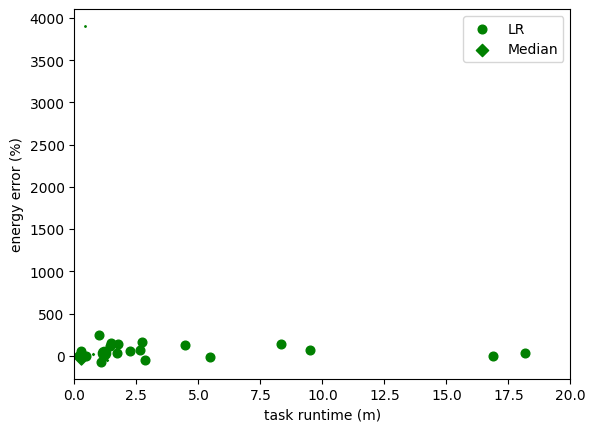

In [113]:
# diana -> jupiter
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'rnaseq', local_profile, target_profile, (GBR, LR), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['rnaseq'], wf_executions[HU]['rnaseq'][1], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('rnaseq', data_df, runtime_vals, energy_vals, missing_tasks, 20, 'upper right', 'diana-jupiter')

chipseq tasks: 2055
LR: 1621 (78.88%) | Median: 185 (9.00%) | Weak Linear Rel.: 249 (12.12%)
missing 298
task cumulative runtime error 20.05% (np.float64(388243.2064134721), np.float64(323410.207))
task cumulative energy error 23.61% (np.float64(1.7421382811524357), np.float64(1.4094186175979542))


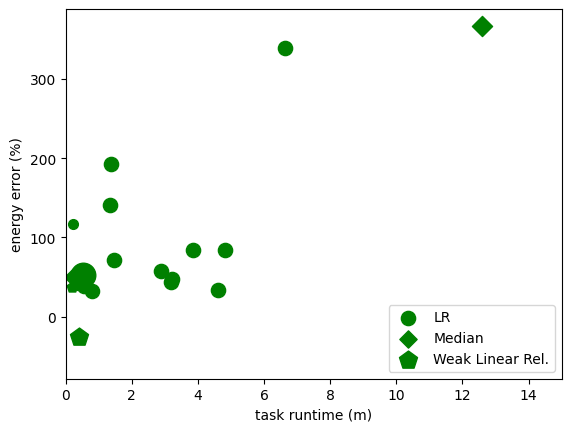

In [114]:
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'chipseq', local_profile, target_profile, (GBR, LR), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['chipseq'], wf_executions[HU]['chipseq'][2], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('chipseq', data_df, runtime_vals, energy_vals, missing_tasks, 15, 'lower right', 'diana-jupiter')

nanoseq tasks: 70
LR: 57 (81.43%) | Median: 4 (5.71%) | Weak Linear Rel.: 9 (12.86%)
missing 3
task cumulative runtime error 8.28% (np.float64(14122.08974071478), np.float64(13042.157))
task cumulative energy error 28.56% (np.float64(0.05684325352051996), np.float64(0.044216251293112054))


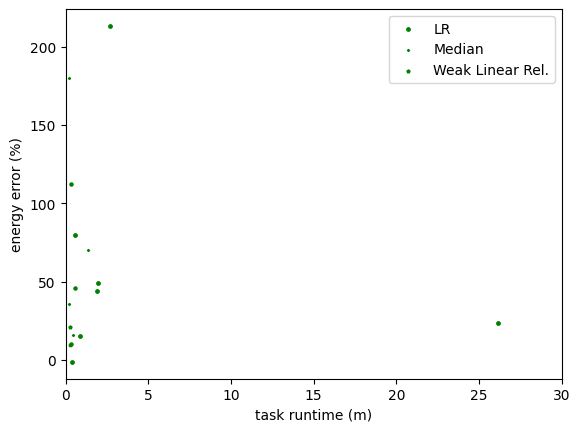

In [115]:
# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'nanoseq', local_profile, target_profile, (GBR, LR), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['nanoseq'], wf_executions[HU]['nanoseq'][1], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('nanoseq', data_df, runtime_vals, energy_vals, missing_tasks, 30, 'upper right', 'diana-jupiter')

atacseq tasks: 184
LR: 103 (55.98%) | Median: 66 (35.87%) | Weak Linear Rel.: 15 (8.15%)
missing 3
task cumulative runtime error 12.08% (np.float64(26109.21221192544), np.float64(23294.569))
task cumulative energy error 55.57% (np.float64(0.11543604944453244), np.float64(0.07419961765855795))


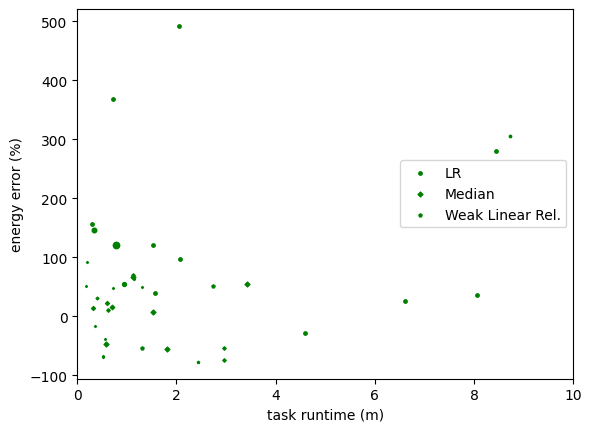

In [116]:
# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'atacseq', local_profile, target_profile, (GBR, LR), False)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['atacseq'], wf_executions[HU]['atacseq'][2], local_profile, hu_reflector_models)
plot_task_times_with_energy_error('atacseq', data_df, runtime_vals, energy_vals, missing_tasks, 10, 'right', 'diana-jupiter')

Profiling Overhead

In [117]:
def get_wf_runtime(wf_df):
    start = wf_df['start'].min()
    complete = wf_df['complete'].max()
    return (complete - start) / 1000 / 60  # return runtime in minutes

profiling_data = { # MiB
    # rnaseq (b, d, e)
    # 'sample_a': 107 + 113.7, 
    'sample_b': 111.1 + 117.9, 
    # 'sample_c': 95.6 + 101.4,
    'sample_d': 81.1 + 85.8,
    'sample_e': 160.8 + 170.2,
    # chipseq (g, i, j)
    # 'sample_f': 96.4, 
    'sample_g': 100.3,
    # 'sample_h': 72.9,
    'sample_i': 77.6,
    'sample_j': 129.6, 
    # nanoseq (k, l, m)
    'sample_k': 290.2 + 177.4,
    'sample_l': 232.1 + 141.8,
    'sample_m': 193.5 + 118.4,
    # 'sample_n': 166.1 + 101, 
    # 'sample_o': 145.2 + 88.3,
    # atacseq (q, r, t)
    # 'sample_p': 157.4 + 161.7 + 148.8 + 154.4,
    'sample_q': 125.6 + 129 + 118.6 + 123.2,
    'sample_r': 106.9 + 109.7 + 101 + 104.8, 
    # 'sample_s': 92.3 + 94.7 + 87.2 + 90.5,
    'sample_t': 79.3 + 81.5 + 74.9 + 77.8,
}
workflow_data = { # GiB
    'rnaseq': 1 + 1.1 + 0.8304 + 0.8869 + 1.2 + 1.3 + 1.2 + 1.3 + 1.3 + 1.4 + 1.4 + 1.5,
    'chipseq': 1 + 1.1 + 1 + 1.2 + 1.1 + 1.1 + 1.3 + 1.3 + 1,
    'nanoseq': 2.2 + 2.2 + 1 + 1.3 + 0.5272 + 2.2,
    'atacseq': 1.1 + 1.1 + 1.0 + 1.1 + 1.4 + 1.6 + 1.2 + 1.4 + 0.2059 + 0.2285 + 0.3649 + 0.3992
}

In [118]:
prof_data = []
prof_oh_headers = ['node', 'wf', 'sample', 'data', 'full_data', 'data OH', 'time', 'energy']

for node, paper_node, gov in zip([AWS_m5_4xl, AWS_c5d, GPG_18, HU_40], 
                                 ['minerva', 'diana', 'neptune', 'jupiter'], 
                                 ['baseline', 'default_linear', 'ondemand_linear', 'performance_linear']):
    profiling_runs = wf_profiles[node]['executions']

    for workflow in ['atacseq', 'chipseq', 'nanoseq', 'rnaseq']:
        for sample in profiling_runs[workflow].keys():
            run = profiling_runs[workflow][sample]
            mini_runtime = round(get_wf_runtime(run), 2)
            mini_size = round(profiling_data[sample] / 1000, 2)
            full_size = round(workflow_data[workflow], 2)
            data_ratio = round((mini_size / full_size) * 100, 2)
            short_sample = sample.split('_')[1]
            ichnos = load_profiling_ichnos_summary(paper_node, workflow, short_sample, gov)
            energy = ichnos['total']
            prof_data.append([paper_node, workflow, sample, mini_size, full_size, data_ratio, mini_runtime, energy])

prof_df = pd.DataFrame(prof_data, columns=prof_oh_headers)

In [119]:
wfs = ['atacseq', 'chipseq', 'nanoseq', 'rnaseq']
neptune_full_wfs = {}
jupiter_full_wfs = {}

for workflow in wfs:
    neptune_full_wfs[workflow] = {
        "time": round(get_wf_runtime(wf_executions[GPG][workflow][1]['run']) * 4, 2), 
        "energy": wf_executions[GPG][workflow][1]['ichnos']['total']
    }
    jupiter_full_wfs[workflow] = {
        "time": round(get_wf_runtime(wf_executions[HU][workflow][1]['run']) * 4, 2), 
        "energy": wf_executions[HU][workflow][1]['ichnos']['total']
    }

grouped = prof_df.groupby(['node', 'wf'])

print('target: neptune')
print('local & workflow & data & data_oh & time & time_oh & energy & energy_oh \\\\')
for node in ['jupiter', 'diana', 'minerva']:
    for workflow in wfs:
        prof_runs = grouped.get_group((node, workflow))
        total_prof_data = prof_runs['data'].sum()
        data_oh = (total_prof_data / prof_runs.iloc[0]['full_data']) * 100
        total_prof_time = prof_runs['time'].sum()
        time_oh = (total_prof_time / neptune_full_wfs[workflow]['time']) * 100
        total_prof_energy = prof_runs['energy'].sum()
        energy_oh = (total_prof_energy / neptune_full_wfs[workflow]['energy']) * 100
        print(f'{node} & {workflow} & {total_prof_data:.2f} & {data_oh:.2f} & {total_prof_time:.2f} & {time_oh:.2f} & {total_prof_energy:.2f} & {energy_oh:.2f} \\\\')

print('==============================')
print('target: jupiter')
print('local & workflow & data & data_oh & time & time_oh & energy & energy_oh \\\\')
for node in ['neptune', 'diana', 'minerva']:
    for workflow in wfs:
        prof_runs = grouped.get_group((node, workflow))
        total_prof_data = prof_runs['data'].sum()
        data_oh = (total_prof_data / prof_runs.iloc[0]['full_data']) * 100
        total_prof_time = prof_runs['time'].sum()
        time_oh = (total_prof_time / jupiter_full_wfs[workflow]['time']) * 100
        total_prof_energy = prof_runs['energy'].sum()
        energy_oh = (total_prof_energy / jupiter_full_wfs[workflow]['energy']) * 100
        print(f'{node} & {workflow} & {total_prof_data:.2f} & {data_oh:.2f} & {total_prof_time:.2f} & {time_oh:.2f} & {total_prof_energy:.2f} & {energy_oh:.2f} \\\\')

target: neptune
local & workflow & data & data_oh & time & time_oh & energy & energy_oh \\
jupiter & atacseq & 1.23 & 11.08 & 36.77 & 3.80 & 0.09 & 6.24 \\
jupiter & chipseq & 0.31 & 3.07 & 50.97 & 4.03 & 0.11 & 5.50 \\
jupiter & nanoseq & 1.15 & 12.20 & 18.02 & 2.07 & 0.04 & 4.51 \\
jupiter & rnaseq & 0.73 & 5.06 & 92.41 & 9.15 & 0.21 & 13.62 \\
diana & atacseq & 1.23 & 11.08 & 39.59 & 4.09 & 0.14 & 9.90 \\
diana & chipseq & 0.31 & 3.07 & 50.91 & 4.03 & 0.17 & 8.36 \\
diana & nanoseq & 1.15 & 12.20 & 24.60 & 2.83 & 0.08 & 8.81 \\
diana & rnaseq & 0.73 & 5.06 & 104.05 & 10.30 & 0.34 & 22.29 \\
minerva & atacseq & 1.23 & 11.08 & 89.53 & 9.26 & 0.16 & 10.94 \\
minerva & chipseq & 0.31 & 3.07 & 77.14 & 6.10 & 0.13 & 6.73 \\
minerva & nanoseq & 1.15 & 12.20 & 37.90 & 4.36 & 0.05 & 5.36 \\
minerva & rnaseq & 0.73 & 5.06 & 170.61 & 16.89 & 0.21 & 13.82 \\
target: jupiter
local & workflow & data & data_oh & time & time_oh & energy & energy_oh \\
neptune & atacseq & 1.23 & 11.08 & 170.82 & 38.

In [120]:
# prepare data for naive baseline
training_columns = ['workflow', 'run', 'total_bytes_read', 'total_bytes_written', 'rapl']

# load HU cluster data
baseline_training_runs = [((work, iter), wf_executions[HU][work][iter]) for work in ['rnaseq', 'chipseq', 'nanoseq', 'atacseq'] for iter in [1, 2, 3]]
all_training_data = []

for (workflow, id), item in baseline_training_runs:
    total_bytes_read = item['run']['read_bytes'].sum()
    total_bytes_written = item['run']['write_bytes'].sum()
    rapl = item['rapl'].iloc[0]['total']
    all_training_data.append([workflow, id, total_bytes_read, total_bytes_written, rapl])

training_data_hu = pd.DataFrame(all_training_data, columns=training_columns)
extra_hu = pd.read_csv('../hu-cluster/extra/exported.csv', header=0)
training_data_hu_variant = pd.concat([training_data_hu, extra_hu])

# load GPG cluster data
baseline_training_runs = [((work, iter), wf_executions[GPG][work][iter]) for work in ['rnaseq', 'chipseq', 'nanoseq', 'atacseq'] for iter in [1, 2, 3]]
all_training_data = []

for (workflow, id), item in baseline_training_runs:
    total_bytes_read = item['run']['read_bytes'].sum()
    total_bytes_written = item['run']['write_bytes'].sum()
    if gu_socket[workflow] == 'both':
        rapl_core = item['rapl'].iloc[0][f'active_pkg_1'] + item['rapl'].iloc[0][f'active_pkg_2']
        if item['rapl'].iloc[0][f'idle_dram_1'] + item['rapl'].iloc[0][f'idle_dram_2'] > item['rapl'].iloc[0][f'dram_1'] + item['rapl'].iloc[0][f'dram_2']:
            rapl_mem = item['rapl'].iloc[0][f'dram_1'] + item['rapl'].iloc[0][f'dram_2']
        else:
            rapl_mem = item['rapl'].iloc[0][f'active_dram_1'] + item['rapl'].iloc[0][f'active_dram_2']
    else:
        rapl_socket = gu_socket[workflow]
        rapl_core = item['rapl'].iloc[0][f'active_pkg{rapl_socket}']
        if item['rapl'].iloc[0][f'idle_dram{rapl_socket}'] > item['rapl'].iloc[0][f'dram{rapl_socket}']:
            rapl_mem = item['rapl'].iloc[0][f'dram{rapl_socket}']
        else:
            rapl_mem = item['rapl'].iloc[0][f'active_dram{rapl_socket}']
    rapl = rapl_core + rapl_mem
    all_training_data.append([workflow, id, total_bytes_read, total_bytes_written, rapl])

training_data_gpg = pd.DataFrame(all_training_data, columns=training_columns)

In [121]:
def get_run_and_subset(raw_data, workflow, iteration):
    real_run = raw_data[raw_data['workflow'] == workflow].iloc[iteration]
    subset = raw_data[raw_data['workflow'] != workflow]
    return real_run, subset

def predict_barbosa(workflow, training_data, model):
    predicted_energy = []
    actual_energy = []

    for iteration in range(0, 3):
        real_run, subset = get_run_and_subset(training_data, workflow, iteration)
        test_x = subset[['total_bytes_read', 'total_bytes_written']]
        test_y = subset['rapl']

        if model == GBR:
            test_model = GradientBoostingRegressor(n_estimators=500, max_depth=4, learning_rate=0.01, loss='squared_error', min_samples_split=5)
        elif model == LR:
            test_model = LinearRegression(fit_intercept=True)
        elif model == RF:
            test_model = RandomForestRegressor()
        else: 
            return

        test_model = test_model.fit(test_x, test_y)
        pred_energy = test_model.predict(np.array([real_run['total_bytes_read'], real_run['total_bytes_written']]).reshape(1, -1))
        predicted_energy.append(pred_energy)

    avg_pred_energy = np.mean(predicted_energy)
    print(f'{workflow},{avg_pred_energy:.2f}')

In [122]:
def run_naive_with_model(model, training_data):
    print(f'\nBarbosa/Naive with model: {model} - HU')

    predict_barbosa('rnaseq', training_data, model)
    predict_barbosa('chipseq', training_data, model)
    predict_barbosa('nanoseq', training_data, model)
    predict_barbosa('atacseq', training_data, model)

In [123]:
print('original') # there are 9 runs here, same as augur + reflector enabled
run_naive_with_model(GBR, training_data_hu)
run_naive_with_model(LR, training_data_hu)
run_naive_with_model(RF, training_data_hu)

original

Barbosa/Naive with model: GradientBoostingRegressor - HU
rnaseq,5.82
chipseq,1.82
nanoseq,1.09
atacseq,0.93

Barbosa/Naive with model: LinearRegression - HU
rnaseq,8.19
chipseq,2.97
nanoseq,0.76
atacseq,1.18

Barbosa/Naive with model: RandomForest - HU
rnaseq,5.74
chipseq,1.91
nanoseq,1.32
atacseq,0.98


In [124]:
print('variant') # there are 10 more runs here -> 19 
run_naive_with_model(GBR, training_data_hu_variant)
run_naive_with_model(LR, training_data_hu_variant)
run_naive_with_model(RF, training_data_hu_variant)

variant

Barbosa/Naive with model: GradientBoostingRegressor - HU
rnaseq,4.72
chipseq,1.85
nanoseq,2.36
atacseq,0.93

Barbosa/Naive with model: LinearRegression - HU
rnaseq,5.90
chipseq,2.43
nanoseq,2.05
atacseq,2.05

Barbosa/Naive with model: RandomForest - HU
rnaseq,4.66
chipseq,1.92
nanoseq,2.30
atacseq,1.06
